<a href="https://colab.research.google.com/github/naimazanaa2006-maker/tp1-Apprentissage-automatique/blob/main/TP2_Pretraitement_Avance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()

Saving transactions_TP2.csv to transactions_TP2.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('transactions_TP2.csv')

print("Dataset chargé avec succès !")

Dataset chargé avec succès !


In [5]:
df.head()

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0.0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0.0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0.0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0.0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0.0


In [6]:
df.tail()

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
3040,OP02381,C10304,1824.17,80.0,6.0,16,agence,ordinateur,Draa-Tafilalet,non,aucune_fraude,0.0
3041,OP02125,C10573,697.27,84.0,4.0,19,NaN,mobile,Marrakech-Safi,non,aucune_fraude,0.0
3042,OP00952,C10125,1624.43,129.0,2.0,7,application,mobile,Draa-Tafilalet,oui,fraude_confirme,NaN
3043,OP00794,C10318,NaN,167.0,2.0,13,application,mobile,Souss-Massa,non,aucune_fraude,0.0
3044,OP02305,C10573,465.84,130.0,4.0,16,site_web,terminal,Souss-Massa,non,aucune_fraude,0.0


In [7]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

Nombre de lignes : 3045
Nombre de colonnes : 12


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3045 entries, 0 to 3044
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id_operation      3045 non-null   object 
 1   id_client         3045 non-null   object 
 2   montant_dh        2935 non-null   float64
 3   anciennete_mois   2908 non-null   float64
 4   nb_ops_24h        2992 non-null   float64
 5   heure             3045 non-null   int64  
 6   canal             2886 non-null   object 
 7   appareil          2923 non-null   object 
 8   region            2942 non-null   object 
 9   international     3045 non-null   object 
 10  resultat_enquete  3045 non-null   object 
 11  fraude            2781 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 285.6+ KB


In [9]:
print("Les colonnes du dataset :")
print(df.columns.tolist())

Les colonnes du dataset :
['id_operation', 'id_client', 'montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'canal', 'appareil', 'region', 'international', 'resultat_enquete', 'fraude']


In [10]:
df.dtypes

,0
id_operation,object
id_client,object
montant_dh,float64
anciennete_mois,float64
nb_ops_24h,float64
heure,int64
canal,object
appareil,object
region,object
international,object


In [11]:
df.describe()

,montant_dh,anciennete_mois,nb_ops_24h,heure,fraude
count,2935.000000,2908.000000,2992.000000,3045.000000,2781.0
mean,1034.646027,88.443948,2.700869,11.422660,0.0
std,1358.953915,50.810303,1.644548,7.000024,0.0
min,36.410000,0.000000,0.000000,0.000000,0.0
25%,389.530000,44.000000,2.000000,5.000000,0.0
50%,709.730000,89.000000,3.000000,11.000000,0.0
75%,1249.585000,133.000000,4.000000,18.000000,0.0
max,33281.230000,174.000000,11.000000,23.000000,0.0


In [12]:
df.describe(include='all')

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
count,3045,3045,2935.000000,2908.000000,2992.000000,3045.000000,2886,2923,2942,3045,3045,2781.0
unique,3000,804,NaN,NaN,NaN,NaN,4,3,5,2,2,NaN
top,OP01074,C10478,NaN,NaN,NaN,NaN,application,mobile,Draa-Tafilalet,non,aucune_fraude,NaN
freq,2,11,NaN,NaN,NaN,NaN,1182,1651,711,2618,2781,NaN
mean,NaN,NaN,1034.646027,88.443948,2.700869,11.422660,NaN,NaN,NaN,NaN,NaN,0.0
std,NaN,NaN,1358.953915,50.810303,1.644548,7.000024,NaN,NaN,NaN,NaN,NaN,0.0
min,NaN,NaN,36.410000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,0.0
25%,NaN,NaN,389.530000,44.000000,2.000000,5.000000,NaN,NaN,NaN,NaN,NaN,0.0
50%,NaN,NaN,709.730000,89.000000,3.000000,11.000000,NaN,NaN,NaN,NaN,NaN,0.0
75%,NaN,NaN,1249.585000,133.000000,4.000000,18.000000,NaN,NaN,NaN,NaN,NaN,0.0


In [13]:
missing_values = df.isnull().sum()

print("Valeurs manquantes par colonne :")
print(missing_values)

Valeurs manquantes par colonne :
id_operation          0
id_client             0
montant_dh          110
anciennete_mois     137
nb_ops_24h           53
heure                 0
canal               159
appareil            122
region              103
international         0
resultat_enquete      0
fraude              264
dtype: int64


In [14]:

missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Pourcentage des valeurs manquantes :")
print(missing_percentage)

Pourcentage des valeurs manquantes :
id_operation        0.000000
id_client           0.000000
montant_dh          3.612479
anciennete_mois     4.499179
nb_ops_24h          1.740558
heure               0.000000
canal               5.221675
appareil            4.006568
region              3.382594
international       0.000000
resultat_enquete    0.000000
fraude              8.669951
dtype: float64


In [15]:
print("Nombre de lignes dupliquées :", df.duplicated().sum())

Nombre de lignes dupliquées : 45


In [16]:
num_cols = df.select_dtypes(include=np.number).columns

print("Variables numériques :")
print(num_cols.tolist())

Variables numériques :
['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'fraude']


In [17]:
cat_cols = df.select_dtypes(include=['object', 'category']).columns

print("Variables catégorielles :")
print(cat_cols.tolist())

Variables catégorielles :
['id_operation', 'id_client', 'canal', 'appareil', 'region', 'international', 'resultat_enquete']


In [18]:
for col in cat_cols:
    print("\nDistribution de", col)
    print(df[col].value_counts(dropna=False))


Distribution de id_operation
id_operation
OP01074    2
OP02872    2
OP00365    2
OP02656    2
OP00082    2
          ..
OP02789    1
OP00712    1
OP01635    1
OP02967    1
OP00092    1
Name: count, Length: 3000, dtype: int64

Distribution de id_client
id_client
C10478    11
C10327    10
C10126    10
C10422    10
C10072     9
          ..
C10384     1
C10463     1
C10761     1
C10748     1
C10432     1
Name: count, Length: 804, dtype: int64

Distribution de canal
canal
application    1182
site_web        896
agence          523
telephone       285
NaN             159
Name: count, dtype: int64

Distribution de appareil
appareil
mobile        1651
ordinateur     918
terminal       354
NaN            122
Name: count, dtype: int64

Distribution de region
region
Draa-Tafilalet       711
Marrakech-Safi       664
Casablanca-Settat    650
Autre                466
Souss-Massa          451
NaN                  103
Name: count, dtype: int64

Distribution de international
international
non    2618

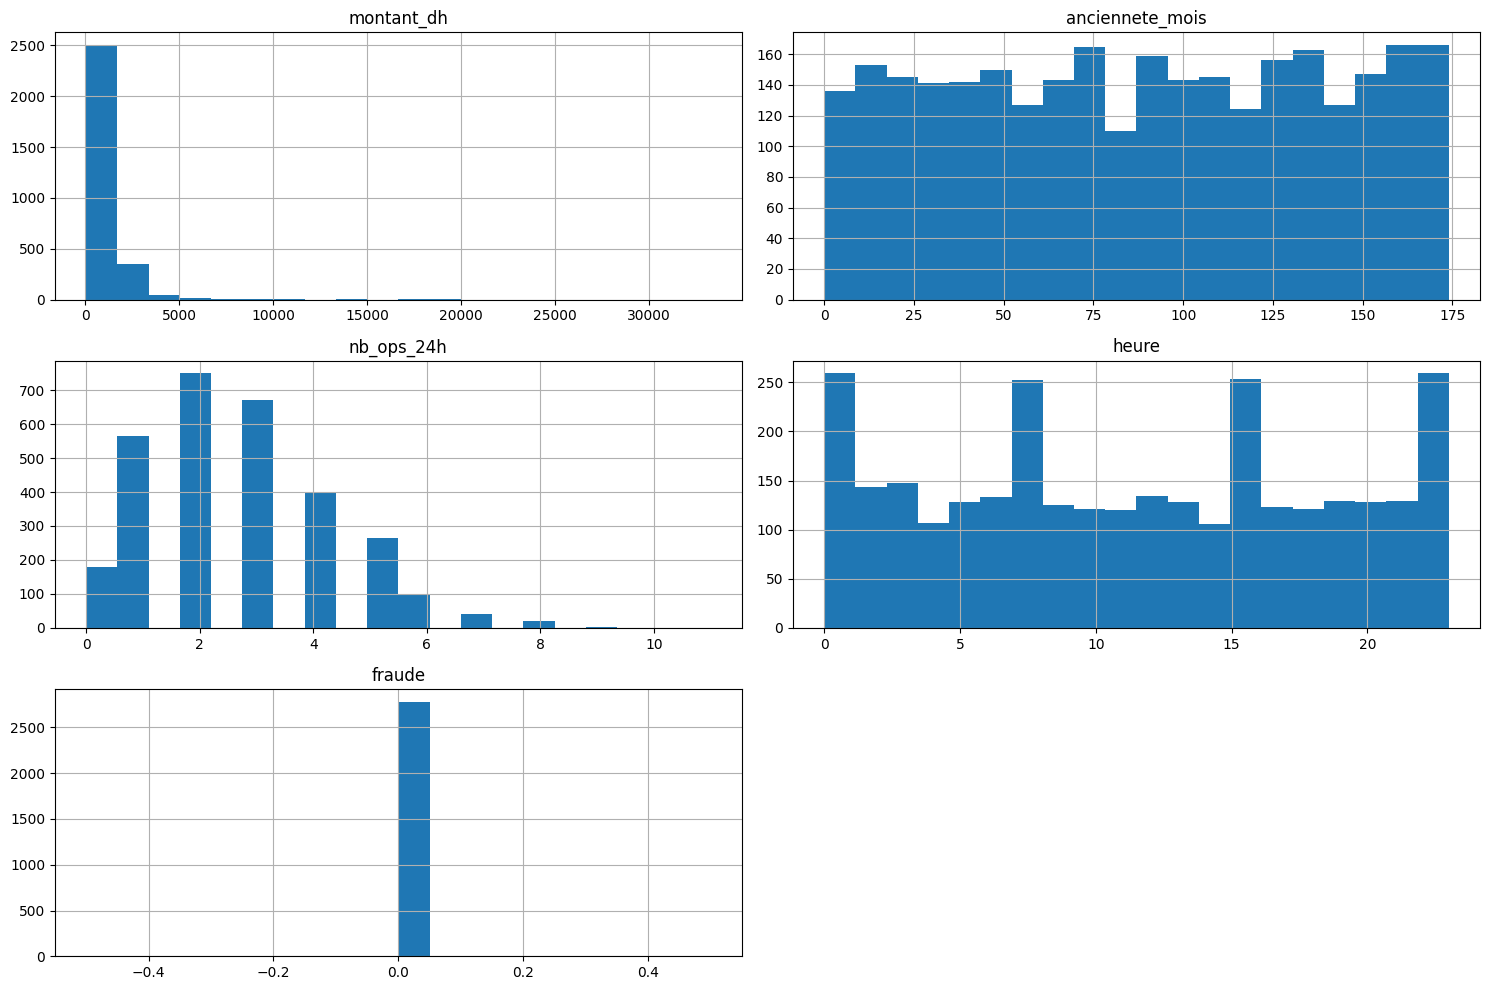

In [19]:
df[num_cols].hist(figsize=(15, 10), bins=20)
plt.tight_layout()
plt.show()

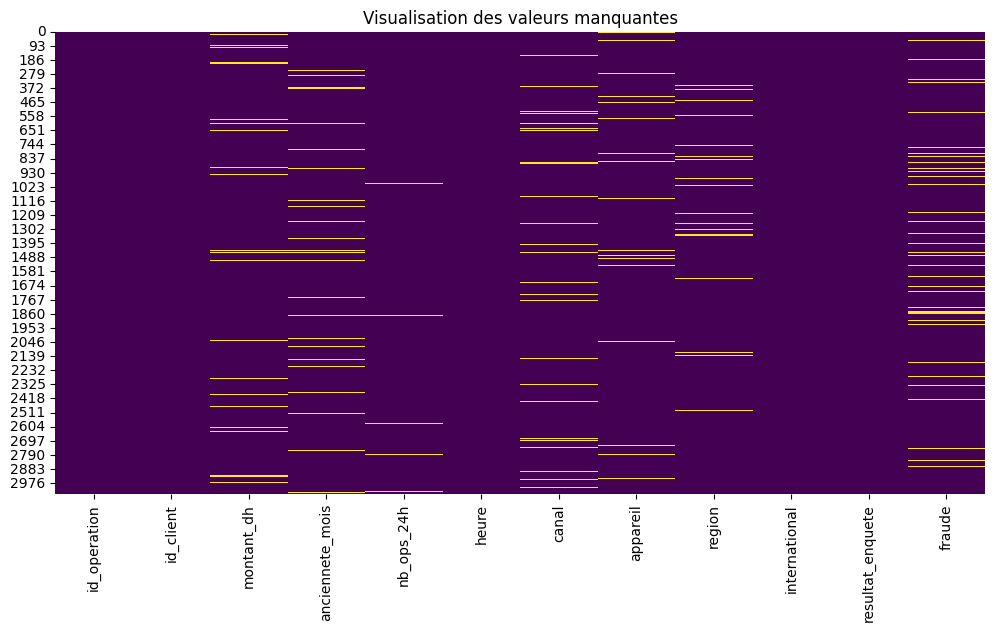

In [20]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False, cmap='viridis')

plt.title("Visualisation des valeurs manquantes")
plt.show()

In [21]:
print("Distribution de la variable resultat_enquete :")
print(df['resultat_enquete'].value_counts(dropna=False))

Distribution de la variable resultat_enquete :
resultat_enquete
aucune_fraude      2781
fraude_confirme     264
Name: count, dtype: int64


In [22]:
if 'fraude' in df.columns:
    print(df['fraude'].value_counts(dropna=False))
else:
    print("La colonne fraude n'existe pas dans le dataset.")

fraude
0.0    2781
NaN     264
Name: count, dtype: int64


In [23]:
print("========== RÉSUMÉ DU DATASET ==========")

print("Dimensions :", df.shape)

print("\nNombre de valeurs manquantes :", df.isnull().sum().sum())

print("Nombre de doublons :", df.duplicated().sum())

print("Nombre de variables numériques :", len(num_cols))

print("Nombre de variables catégorielles :", len(cat_cols))

print("\nExploration terminée.")

========== RÉSUMÉ DU DATASET ==========
Dimensions : (3045, 12)

Nombre de valeurs manquantes : 948
Nombre de doublons : 45
Nombre de variables numériques : 5
Nombre de variables catégorielles : 7

Exploration terminée.


partie2

In [24]:
df_clean = df.copy()

print("Copie du dataset créée avec succès.")

Copie du dataset créée avec succès.


In [25]:
print("Valeurs manquantes par colonne :")
print(df_clean.isnull().sum())

Valeurs manquantes par colonne :
id_operation          0
id_client             0
montant_dh          110
anciennete_mois     137
nb_ops_24h           53
heure                 0
canal               159
appareil            122
region              103
international         0
resultat_enquete      0
fraude              264
dtype: int64


In [26]:
missing_percentage = (df_clean.isnull().sum() / len(df_clean)) * 100

print("Pourcentage des valeurs manquantes :")
print(missing_percentage.round(2))

Pourcentage des valeurs manquantes :
id_operation        0.00
id_client           0.00
montant_dh          3.61
anciennete_mois     4.50
nb_ops_24h          1.74
heure               0.00
canal               5.22
appareil            4.01
region              3.38
international       0.00
resultat_enquete    0.00
fraude              8.67
dtype: float64


In [27]:
print("Nombre de doublons :", df_clean.duplicated().sum())

Nombre de doublons : 45


In [28]:
df_clean = df_clean.drop_duplicates()

print("Nombre de lignes après suppression :", len(df_clean))

Nombre de lignes après suppression : 3000


In [29]:
num_cols = df_clean.select_dtypes(include=np.number).columns.tolist()

cat_cols = df_clean.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Variables numériques :", num_cols)
print("Variables catégorielles :", cat_cols)

Variables numériques : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'fraude']
Variables catégorielles : ['id_operation', 'id_client', 'canal', 'appareil', 'region', 'international', 'resultat_enquete']


In [30]:
for col in num_cols:
    print(col, ":", df_clean[col].isnull().sum())

montant_dh : 107
anciennete_mois : 135
nb_ops_24h : 53
heure : 0
fraude : 258


In [31]:
for col in cat_cols:
    print(col, ":", df_clean[col].isnull().sum())

id_operation : 0
id_client : 0
canal : 156
appareil : 120
region : 102
international : 0
resultat_enquete : 0


In [32]:
for col in num_cols:
    median_value = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_value)

print("Valeurs manquantes numériques traitées.")

Valeurs manquantes numériques traitées.


In [33]:
for col in cat_cols:
    if df_clean[col].isnull().sum() > 0:
        mode_value = df_clean[col].mode()

        if not mode_value.empty:
            df_clean[col] = df_clean[col].fillna(mode_value[0])

print("Valeurs manquantes catégorielles traitées.")

Valeurs manquantes catégorielles traitées.


In [34]:
print("Valeurs manquantes restantes :")
print(df_clean.isnull().sum())

Valeurs manquantes restantes :
id_operation        0
id_client           0
montant_dh          0
anciennete_mois     0
nb_ops_24h          0
heure               0
canal               0
appareil            0
region              0
international       0
resultat_enquete    0
fraude              0
dtype: int64


In [35]:
df_clean.describe(include='all')

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
count,3000,3000,3000.000000,3000.000000,3000.00000,3000.000000,3000,3000,3000,3000,3000,3000.0
unique,3000,804,NaN,NaN,NaN,NaN,4,3,5,2,2,NaN
top,OP02438,C10327,NaN,NaN,NaN,NaN,application,mobile,Draa-Tafilalet,non,aucune_fraude,NaN
freq,1,10,NaN,NaN,NaN,NaN,1321,1748,804,2575,2742,NaN
mean,NaN,NaN,1016.956843,88.484667,2.71100,11.427667,NaN,NaN,NaN,NaN,NaN,0.0
std,NaN,NaN,1298.408862,49.692456,1.63188,6.996362,NaN,NaN,NaN,NaN,NaN,0.0
min,NaN,NaN,36.410000,0.000000,0.00000,0.000000,NaN,NaN,NaN,NaN,NaN,0.0
25%,NaN,NaN,398.605000,46.000000,2.00000,5.000000,NaN,NaN,NaN,NaN,NaN,0.0
50%,NaN,NaN,708.660000,89.000000,3.00000,11.000000,NaN,NaN,NaN,NaN,NaN,0.0
75%,NaN,NaN,1219.660000,131.000000,4.00000,18.000000,NaN,NaN,NaN,NaN,NaN,0.0


In [36]:
print("Dataset original :", df.shape)
print("Dataset nettoyé :", df_clean.shape)

print("\nDoublons avant :", df.duplicated().sum())
print("Doublons après :", df_clean.duplicated().sum())

print("\nValeurs manquantes avant :", df.isnull().sum().sum())
print("Valeurs manquantes après :", df_clean.isnull().sum().sum())

Dataset original : (3045, 12)
Dataset nettoyé : (3000, 12)

Doublons avant : 45
Doublons après : 0

Valeurs manquantes avant : 948
Valeurs manquantes après : 0


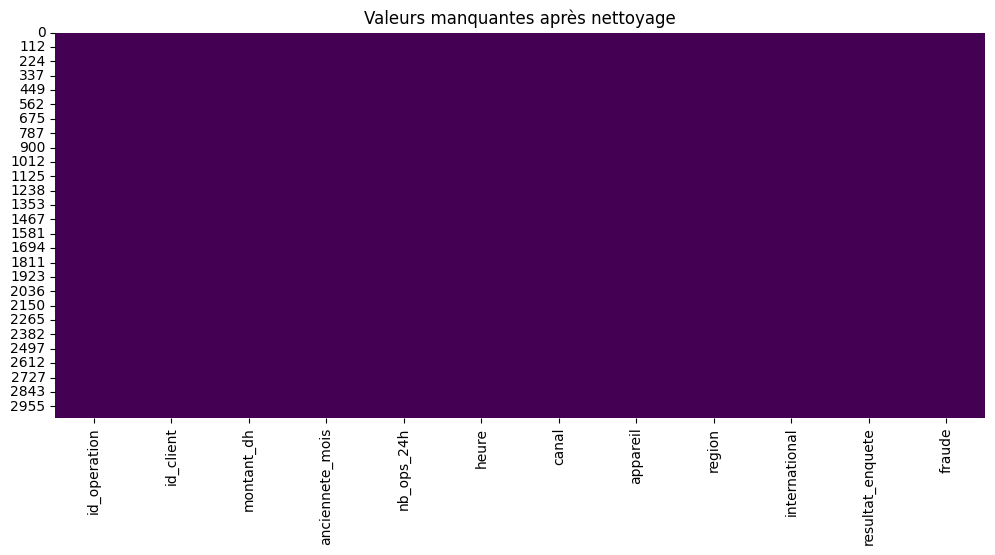

In [37]:
plt.figure(figsize=(12, 5))

sns.heatmap(df_clean.isnull(), cbar=False, cmap='viridis')

plt.title("Valeurs manquantes après nettoyage")
plt.show()

In [38]:
df_clean.to_csv('transactions_clean.csv', index=False)

print("Dataset nettoyé sauvegardé avec succès.")

Dataset nettoyé sauvegardé avec succès.


partie3

In [39]:
num_cols = df_clean.select_dtypes(include=np.number).columns.tolist()

print("Variables numériques :")
print(num_cols)

Variables numériques :
['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'fraude']


In [40]:
df_clean[num_cols].describe()

,montant_dh,anciennete_mois,nb_ops_24h,heure,fraude
count,3000.000000,3000.000000,3000.00000,3000.000000,3000.0
mean,1016.956843,88.484667,2.71100,11.427667,0.0
std,1298.408862,49.692456,1.63188,6.996362,0.0
min,36.410000,0.000000,0.00000,0.000000,0.0
25%,398.605000,46.000000,2.00000,5.000000,0.0
50%,708.660000,89.000000,3.00000,11.000000,0.0
75%,1219.660000,131.000000,4.00000,18.000000,0.0
max,33281.230000,174.000000,11.00000,23.000000,0.0


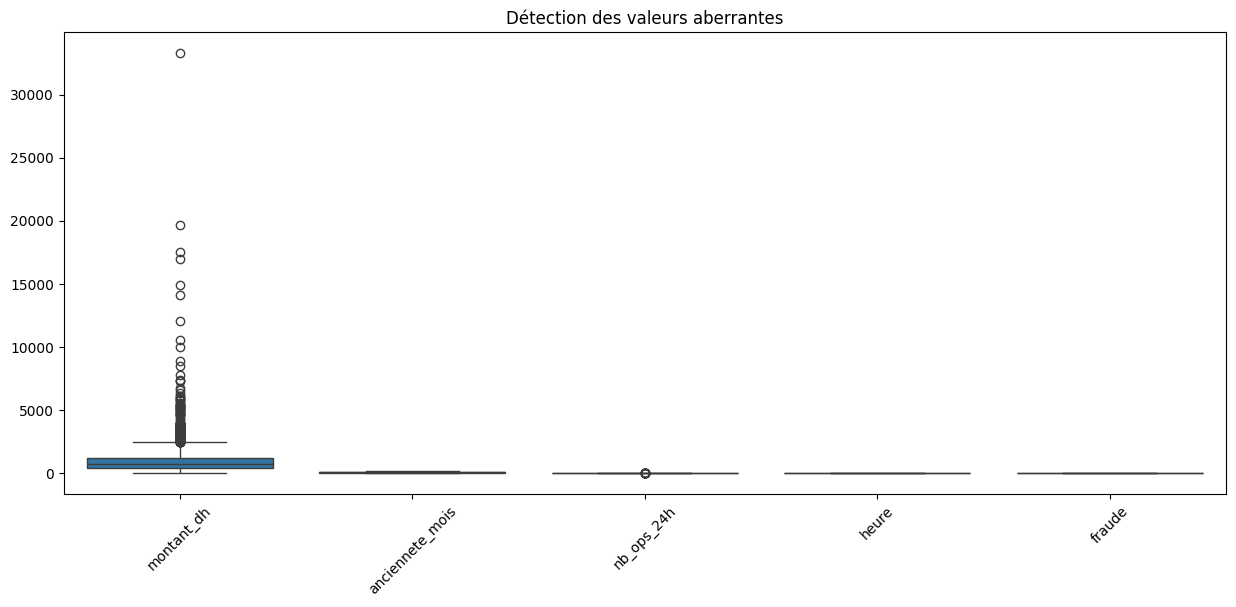

In [41]:
plt.figure(figsize=(15, 6))

sns.boxplot(data=df_clean[num_cols])

plt.title("Détection des valeurs aberrantes")
plt.xticks(rotation=45)
plt.show()

In [42]:
outliers_info = {}

for col in num_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    outliers_info[col] = len(outliers)

    print("\nVariable :", col)
    print("Limite inférieure :", lower_bound)
    print("Limite supérieure :", upper_bound)
    print("Nombre d'outliers :", len(outliers))


Variable : montant_dh
Limite inférieure : -832.9774999999997
Limite supérieure : 2451.2424999999994
Nombre d'outliers : 201

Variable : anciennete_mois
Limite inférieure : -81.5
Limite supérieure : 258.5
Nombre d'outliers : 0

Variable : nb_ops_24h
Limite inférieure : -1.0
Limite supérieure : 7.0
Nombre d'outliers : 24

Variable : heure
Limite inférieure : -14.5
Limite supérieure : 37.5
Nombre d'outliers : 0

Variable : fraude
Limite inférieure : 0.0
Limite supérieure : 0.0
Nombre d'outliers : 0


In [43]:
outliers_df = pd.DataFrame(
    list(outliers_info.items()),
    columns=['Variable', 'Nombre_outliers']
)

print(outliers_df)

          Variable  Nombre_outliers
0       montant_dh              201
1  anciennete_mois                0
2       nb_ops_24h               24
3            heure                0
4           fraude                0


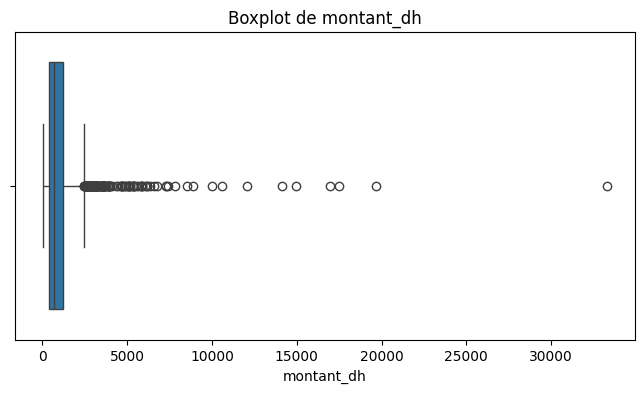

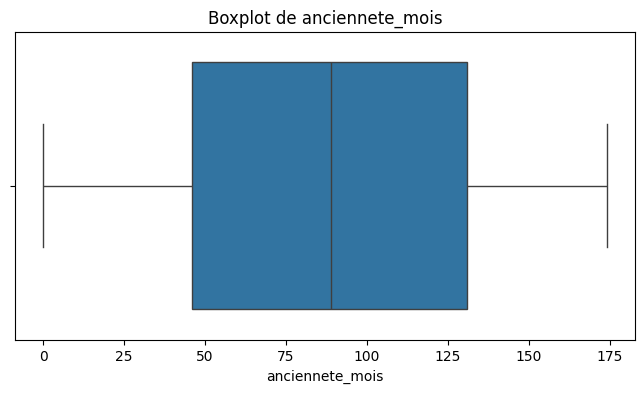

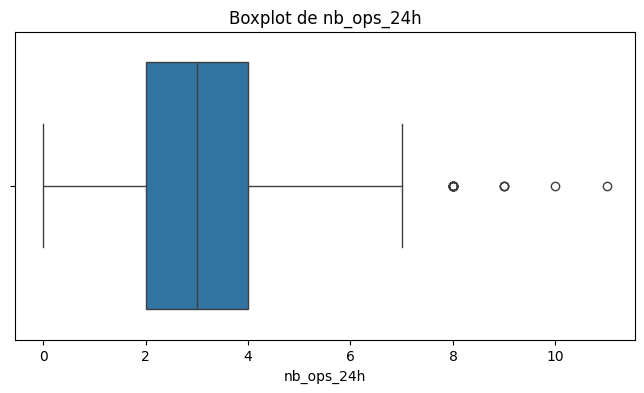

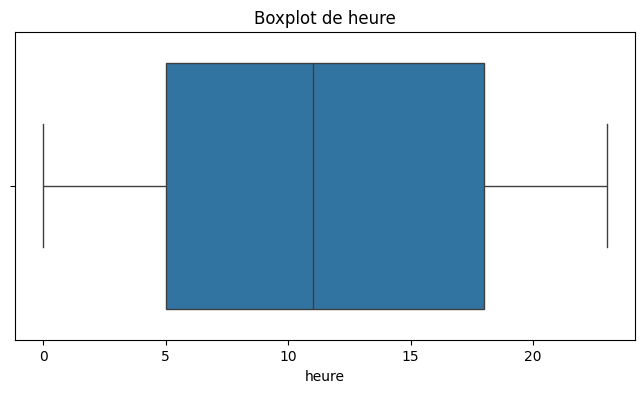

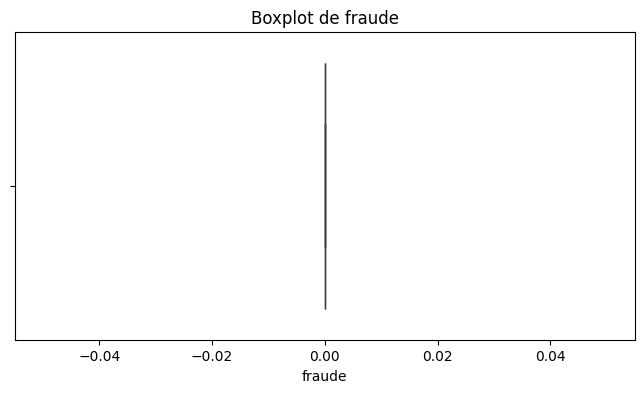

In [44]:
for col in num_cols:
    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df_clean[col])

    plt.title("Boxplot de " + col)
    plt.show()

In [45]:
df_treated = df_clean.copy()

for col in num_cols:
    Q1 = df_treated[col].quantile(0.25)
    Q3 = df_treated[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_treated[col] = df_treated[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

print("Traitement des valeurs aberrantes terminé.")

Traitement des valeurs aberrantes terminé.


In [46]:
for col in num_cols:
    Q1 = df_treated[col].quantile(0.25)
    Q3 = df_treated[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    count = (
        (df_treated[col] < lower_bound) |
        (df_treated[col] > upper_bound)
    ).sum()

    print(col, ":", count, "outliers restants")

montant_dh : 0 outliers restants
anciennete_mois : 0 outliers restants
nb_ops_24h : 0 outliers restants
heure : 0 outliers restants
fraude : 0 outliers restants


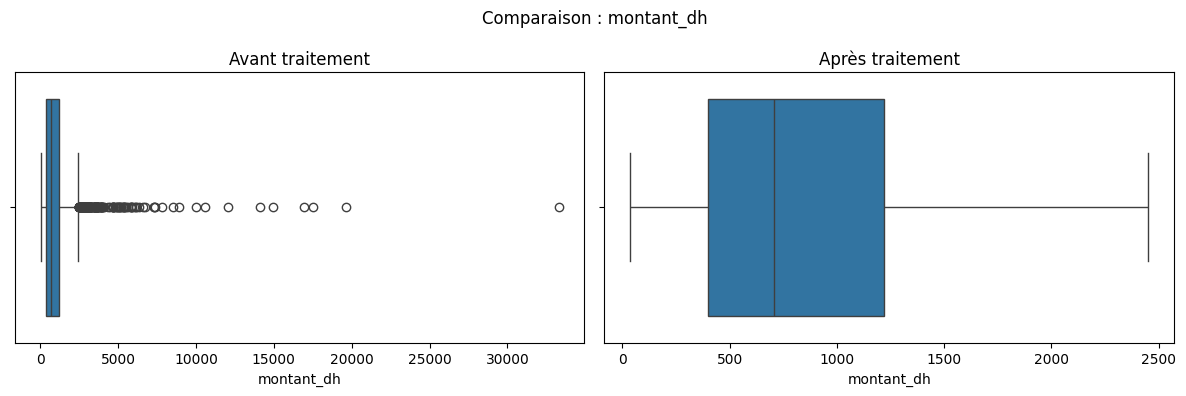

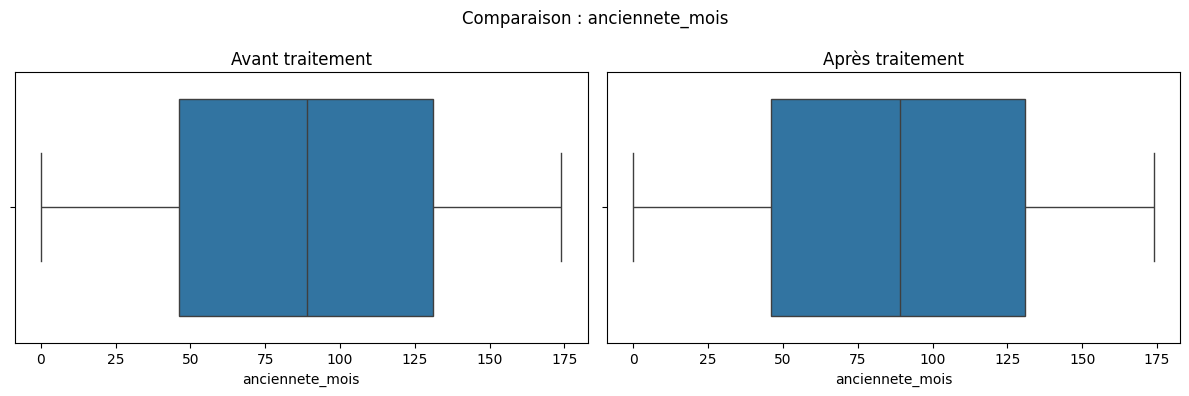

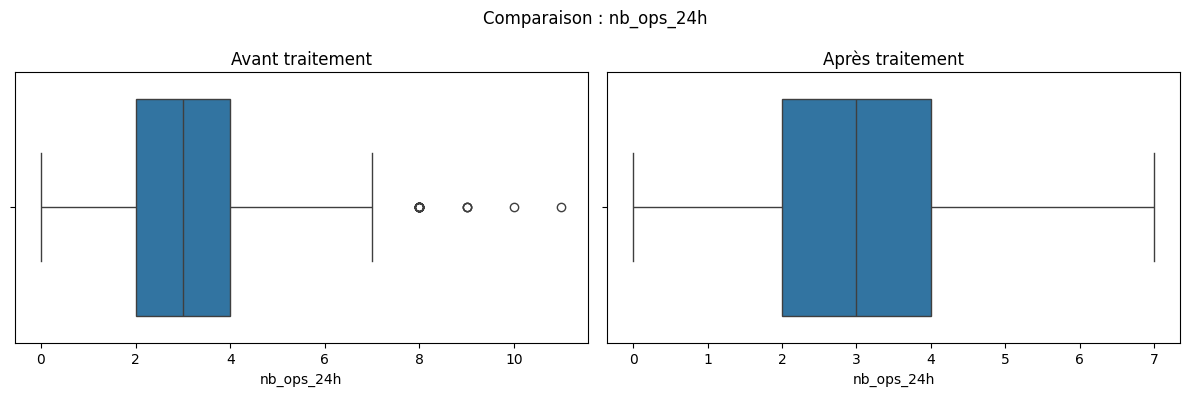

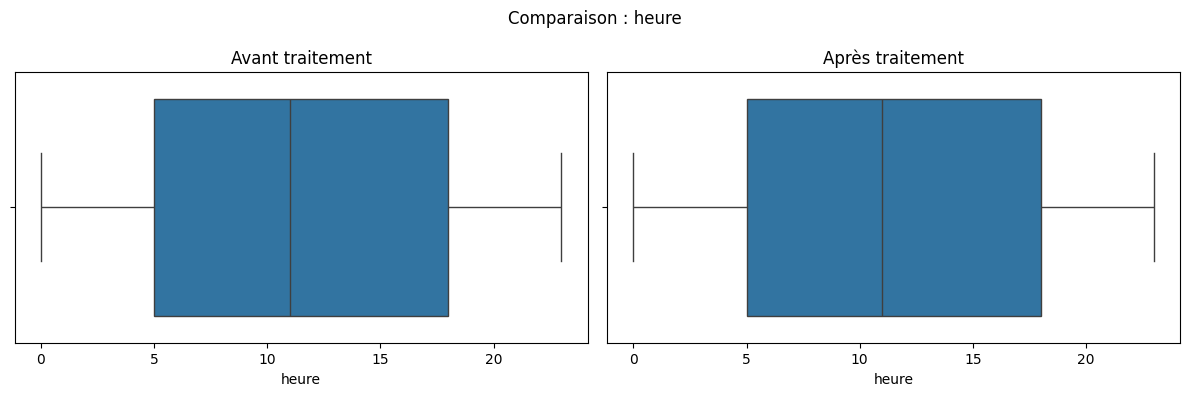

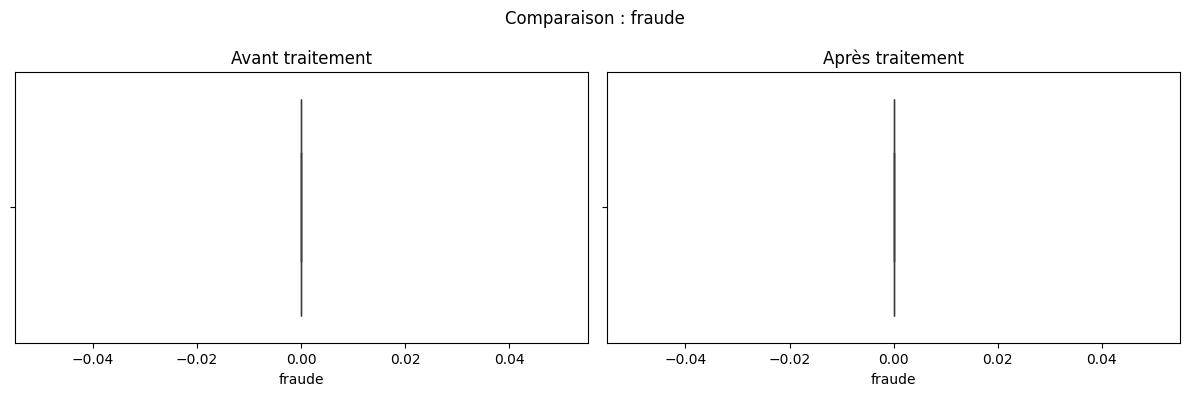

In [47]:
for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.boxplot(x=df_clean[col], ax=axes[0])
    axes[0].set_title("Avant traitement")

    sns.boxplot(x=df_treated[col], ax=axes[1])
    axes[1].set_title("Après traitement")

    plt.suptitle("Comparaison : " + col)
    plt.tight_layout()
    plt.show()

In [49]:
df_treated.to_csv('transactions_outliers_treated.csv', index=False)

print("Dataset sauvegardé avec succès.")

Dataset sauvegardé avec succès.


partie4


In [59]:
import pandas as pd
import numpy as np

df_original = pd.read_csv('transactions_TP2.csv')

df_original['resultat_enquete'] = (
    df_original['resultat_enquete']
    .astype('string')
    .str.strip()
    .str.lower()
)

print(df_original['resultat_enquete'].value_counts(dropna=False))

resultat_enquete
aucune_fraude      2781
fraude_confirme     264
Name: count, dtype: Int64


In [60]:
df_original['fraude'] = df_original['resultat_enquete'].map({
    'aucune_fraude': 0,
    'fraude_confirme': 1,
    'fraude_confirmee': 1
})

print("Distribution de la variable fraude :")
print(df_original['fraude'].value_counts(dropna=False))

Distribution de la variable fraude :
fraude
0    2781
1     264
Name: count, dtype: int64


In [61]:
print(pd.crosstab(
    df_original['resultat_enquete'],
    df_original['fraude'],
    dropna=False
))

fraude               0    1
resultat_enquete           
aucune_fraude     2781    0
fraude_confirme      0  264


In [64]:
from sklearn.model_selection import train_test_split

df_part4 = df_original.dropna(subset=['fraude']).copy()

X = df_part4.drop(columns=[
    'fraude',
    'resultat_enquete',
    'id_operation',
    'id_client'
])

y = df_part4['fraude'].astype(int)

X_ref, X_test, y_ref, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Taille du groupe de référence :", len(X_ref))
print("Taille du groupe de test :", len(X_test))

Taille du groupe de référence : 2436
Taille du groupe de test : 609


In [65]:
# Distribution des classes dans le groupe de référence

print("Nombre de transactions par classe :")
print(y_ref.value_counts().sort_index())

print("\nPourcentage de chaque classe :")
print((y_ref.value_counts(normalize=True).sort_index() * 100).round(2))

Nombre de transactions par classe :
fraude
0    2225
1     211
Name: count, dtype: int64

Pourcentage de chaque classe :
fraude
0    91.34
1     8.66
Name: proportion, dtype: float64


In [66]:
from imblearn.over_sampling import RandomOverSampler

# Création du RandomOverSampler
ros = RandomOverSampler(random_state=42)

# Application sur le groupe de référence uniquement
X_over, y_over = ros.fit_resample(X_ref, y_ref)

print("Avant RandomOverSampler :")
print(y_ref.value_counts())

print("\nAprès RandomOverSampler :")
print(y_over.value_counts())

Avant RandomOverSampler :
fraude
0    2225
1     211
Name: count, dtype: int64

Après RandomOverSampler :
fraude
0    2225
1    2225
Name: count, dtype: int64


In [67]:
from imblearn.under_sampling import RandomUnderSampler

# Création du RandomUnderSampler
rus = RandomUnderSampler(random_state=42)

# Application sur le groupe de référence original
X_under, y_under = rus.fit_resample(X_ref, y_ref)

print("Avant RandomUnderSampler :")
print(y_ref.value_counts())

print("\nAprès RandomUnderSampler :")
print(y_under.value_counts())

print("\nNombre de lignes supprimées :")
print(len(X_ref) - len(X_under))

Avant RandomUnderSampler :
fraude
0    2225
1     211
Name: count, dtype: int64

Après RandomUnderSampler :
fraude
0    211
1    211
Name: count, dtype: int64

Nombre de lignes supprimées :
2014


In [68]:
import pandas as pd
from imblearn.over_sampling import SMOTE

# Petit exemple avec deux variables numériques
X_demo = pd.DataFrame({
    'montant': [100, 120, 130, 140, 150, 160, 170, 180],
    'anciennete': [2, 3, 4, 5, 6, 7, 8, 9]
})

y_demo = pd.Series([0, 0, 0, 0, 0, 1, 1, 1])

print("Avant SMOTE :")
print(y_demo.value_counts())

# Application de SMOTE
smote = SMOTE(random_state=42, k_neighbors=1)
X_smote, y_smote = smote.fit_resample(X_demo, y_demo)

print("\nAprès SMOTE :")
print(y_smote.value_counts())

print("\nNouvelles lignes générées :")
print(X_smote.iloc[len(X_demo):])

Avant SMOTE :
0    5
1    3
Name: count, dtype: int64

Après SMOTE :
0    5
1    5
Name: count, dtype: int64

Nouvelles lignes générées :
   montant  anciennete
8      178           8
9      167           7


In [69]:
comparaison = pd.DataFrame({
    'Méthode': [
        'Avant rééchantillonnage',
        'RandomOverSampler',
        'RandomUnderSampler'
    ],
    'Classe 0': [
        y_ref.value_counts()[0],
        y_over.value_counts()[0],
        y_under.value_counts()[0]
    ],
    'Classe 1': [
        y_ref.value_counts()[1],
        y_over.value_counts()[1],
        y_under.value_counts()[1]
    ]
})

print(comparaison)

                   Méthode  Classe 0  Classe 1
0  Avant rééchantillonnage      2225       211
1        RandomOverSampler      2225      2225
2       RandomUnderSampler       211       211


In [70]:
print("Distribution du groupe de test :")
print(y_test.value_counts())

print("\nTaille du groupe de test :", len(y_test))

Distribution du groupe de test :
fraude
0    556
1     53
Name: count, dtype: int64

Taille du groupe de test : 609


partie5

In [71]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder

# Sélection des colonnes numériques et catégorielles
num_cols = X_ref.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X_ref.select_dtypes(include=['object', 'category', 'string']).columns

# Pipeline numérique
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# Pipeline catégoriel
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Transformation complète
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

print("Colonnes numériques :", list(num_cols))
print("Colonnes catégorielles :", list(cat_cols))
print("ColumnTransformer créé avec succès.")

Colonnes numériques : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
Colonnes catégorielles : ['canal', 'appareil', 'region', 'international']
ColumnTransformer créé avec succès.


In [72]:
# Apprentissage sur le groupe de référence uniquement
X_ref_transformed = preprocessor.fit_transform(X_ref)

# Transformation du groupe de test
X_test_transformed = preprocessor.transform(X_test)

print("Dimensions du groupe de référence :", X_ref_transformed.shape)
print("Dimensions du groupe de test :", X_test_transformed.shape)

print("\nValeurs manquantes dans Reference :",
      pd.isna(X_ref_transformed).sum())

print("Valeurs manquantes dans Test :",
      pd.isna(X_test_transformed).sum())

Dimensions du groupe de référence : (2436, 18)
Dimensions du groupe de test : (609, 18)

Valeurs manquantes dans Reference : 0
Valeurs manquantes dans Test : 0


In [73]:
# Création d'une nouvelle transaction
nouvelle_transaction = X_ref.iloc[[0]].copy()

# Introduction d'une catégorie inconnue
nouvelle_transaction['canal'] = 'application_inconnue'

# Transformation
nouvelle_transformation = preprocessor.transform(nouvelle_transaction)

print("Transformation réussie !")
print("Dimensions :", nouvelle_transformation.shape)

Transformation réussie !
Dimensions : (1, 18)


In [74]:
import joblib

# Sauvegarder le transformer
joblib.dump(preprocessor, 'preprocessor.pkl')

print("Transformer sauvegardé avec succès.")

Transformer sauvegardé avec succès.


In [75]:
# Recharger le transformer
preprocessor_loaded = joblib.load('preprocessor.pkl')

# Transformer les mêmes données
X_ref_loaded = preprocessor_loaded.transform(X_ref)

# Vérifier que les résultats sont identiques
import numpy as np

print("Résultats identiques :",
      np.allclose(X_ref_transformed, X_ref_loaded))

print("Dimensions après rechargement :", X_ref_loaded.shape)

Résultats identiques : True
Dimensions après rechargement : (2436, 18)
